# The datasets

A look at the data only, no models. For each dataset: what it is, what the event and time mean, size, censoring, follow-up, missing values, what the variables mean, and things to watch out for. At the end: what our loaders do to the data (`src/data.py`), one summary table and a figure for the poster.

| dataset | used in |
|---|---|
| SUPPORT | 01, 04, 05, 06, 08, 09, 10, 11 |
| FLChain, GBSG2, WHAS500 | 01, 07, 08, 09 |
| simulated (official VaDeSC generator) | 02, 03, 06, 08, 09 |

In [1]:
import sys
sys.path.append("..")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from sksurv.datasets import load_flchain, load_gbsg2, load_whas500

from src.data import SUPPORT_DROP, SUPPORT_POST_BASELINE, load_simulated, load_sksurv, load_support, load_support_raw

def as_frame(loader):
    X, y = loader()
    ev, tm = y.dtype.names
    df = X.copy()
    df["time"], df["event"] = y[tm].astype(float), y[ev].astype(int)
    return df

support_raw = load_support_raw()
support = support_raw.drop(columns=[c for c in SUPPORT_DROP if c not in ("d.time", "death")]).rename(columns={"d.time": "time", "death": "event"})
data = {"SUPPORT": support, "FLChain": as_frame(load_flchain), "GBSG2": as_frame(load_gbsg2), "WHAS500": as_frame(load_whas500)}

def median_follow_up(t, e):
    # reverse Kaplan-Meier: treat censoring as the "event"
    return KaplanMeierFitter().fit(t, 1 - e).median_survival_time_

def summary(name, df):
    X = df.drop(columns=["time", "event"])
    num = X.select_dtypes("number").shape[1]
    km = KaplanMeierFitter().fit(df["time"], df["event"])
    return {"dataset": name, "patients": len(df), "variables": X.shape[1], "numeric": num, "categorical": X.shape[1] - num,
            "events (%)": 100 * df["event"].mean(), "censored (%)": 100 * (1 - df["event"].mean()),
            "median follow-up (years)": median_follow_up(df["time"], df["event"]) / 365.25,
            "median survival (years)": km.median_survival_time_ / 365.25,
            "max time (years)": df["time"].max() / 365.25,
            "missing cells (%)": 100 * X.isna().mean().mean(),
            "patients with any missing (%)": 100 * X.isna().any(axis=1).mean()}

def missing(df):
    m = df.drop(columns=["time", "event"]).isna().mean()
    return (100 * m[m > 0]).sort_values(ascending=False).round(1).rename("missing (%)")

def km_plot(df, by=None, title="", ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 4))[1]
    groups = [(None, df)] if by is None else list(df.groupby(by, observed=True))
    for g, d in groups:
        lab = "all patients" if g is None else f"{by} = {g} (n={len(d)})"
        KaplanMeierFitter(label=lab).fit(d["time"] / 365.25, d["event"]).plot_survival_function(ax=ax, ci_show=g is None)
    ax.set(xlabel="years", ylabel="survival probability", ylim=(0, 1.02), title=title)
    return ax

## 1. SUPPORT

**Study to Understand Prognoses and Preferences for Outcomes and Risks of Treatments.** 9,105 seriously ill adults admitted to five US hospitals (1989-1994), in one of nine disease groups (e.g. multi-organ failure, COPD, heart failure, cirrhosis, coma, lung or colon cancer). Collected to study prognosis and end-of-life care decisions.

- **Event**: death (any cause). **Time**: days from study entry to death or last follow-up (`d.time`).
- This is the main dataset of the VaDeSC paper (and of our project). We use the CSV from the official VaDeSC repository.

| variable | meaning |
|---|---|
| `age`, `sex`, `race`, `edu`, `income` | demographics (education in years) |
| `dzgroup`, `dzclass` | disease group (9) and disease class (4: ARF/MOSF, COPD/CHF/cirrhosis, cancer, coma) |
| `num.co`, `diabetes`, `dementia`, `ca` | number of comorbidities, diabetes, dementia, cancer (no / yes / metastatic) |
| `scoma` | SUPPORT coma score (0 = awake, 100 = deepest) |
| `avtisst` | average TISS score: how intensive the care is |
| `hday` | day in hospital at which the patient entered the study |
| `meanbp`, `hrt`, `resp`, `temp` | mean blood pressure, heart rate, respiratory rate, temperature |
| `wblc`, `alb`, `bili`, `crea`, `sod`, `ph`, `glucose`, `bun`, `urine`, `pafi` | lab values: white blood cells, albumin, bilirubin, creatinine, sodium, pH, glucose, urea, urine output, PaO2/FiO2 |
| `adlp`, `adls`, `adlsc` | activities of daily living (patient / surrogate / calibrated), higher = more dependent |
| `sfdm2`, `slos`, `charges`, `totcst` | **post-baseline**: functional status at 2 months, length of stay, hospital charges, total cost |

Dropped by the official loader (outcomes or scores built from them): `hospdead`, `prg2m`, `prg6m`, `dnr`, `dnrday`, `aps`, `sps`, `surv2m`, `surv6m`, `totmcst`.

9105 patients, 35 variables, 68% died during follow-up


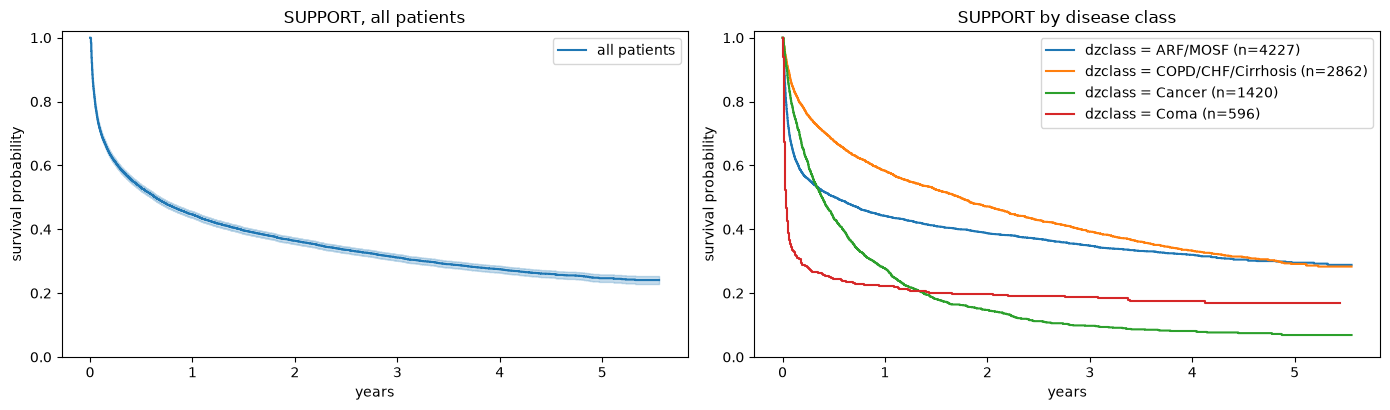

,adlp,urine,glucose,bun,alb,income,adls,bili,pafi,ph,...,charges,avtisst,crea,race,meanbp,scoma,resp,hrt,temp,sod
missing (%),62.0,53.4,49.4,47.8,37.0,32.8,31.5,28.6,25.5,25.1,...,1.9,0.9,0.7,0.5,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
df = data["SUPPORT"]
print(f"{len(df)} patients, {df.shape[1] - 2} variables, {df.event.mean():.0%} died during follow-up")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
km_plot(df, title="SUPPORT, all patients", ax=ax[0])
km_plot(df, by="dzclass", title="SUPPORT by disease class", ax=ax[1])
plt.tight_layout(); plt.show()
missing(df).to_frame().T

**Things to watch out for in SUPPORT**

1. **Post-baseline variables (leakage).** `sfdm2`, `slos`, `charges` and `totcst` are only known after study entry. The `sfdm2` level `"<2 mo. follow-up"` means the patient died within two months (100% of them, see below), so it gives away the outcome for those patients. The paper's preprocessing keeps them; we report both versions (notebooks 01 and 10).
2. **Missing values are informative.** About a third of some lab values are missing, and patients with a missing value died more often (notebook 06).
3. **Rare binary variables.** After standardisation a 0/1 variable with few 1s ends up far from 0 for those patients (e.g. `dementia`: 3% of patients, value about 5.5 for them), which can pull a small cluster around them (notebook 11).

In [3]:
d2 = (df["time"] <= 60) & (df["event"] == 1)
print("death within 60 days, by sfdm2 level:")
display((100 * d2.groupby(df["sfdm2"].fillna("missing")).mean()).round(0).rename("% died within 60 days").to_frame())
dem = df["dementia"]
print(f"dementia: {dem.mean():.1%} of patients; standardised value of a patient with dementia: {(1 - dem.mean()) / dem.std():.1f}")

death within 60 days, by sfdm2 level:


,% died within 60 days
sfdm2,
<2 mo. follow-up,100.0
Coma or Intub,0.0
SIP>=30,0.0
adl>=4 (>=5 if sur),1.0
missing,2.0
no(M2 and SIP pres),0.0


dementia: 3.3% of patients; standardised value of a patient with dementia: 5.5


## 2. FLChain

**Serum free light chain study.** 7,874 residents of Olmsted County, Minnesota, aged 50 or older, whose stored blood samples (1995-2003) were analysed for immunoglobulin free light chains. The question was whether high free light chain levels predict death in the general population (Dispenzieri et al., 2012).

- **Event**: death (any cause). **Time**: days from the blood sample to death or last follow-up (`futime`).
- A population cohort, not hospital patients, so survival is much longer than in SUPPORT.

| variable | meaning |
|---|---|
| `age`, `sex` | |
| `kappa`, `lambda` | serum free light chain kappa and lambda (mg/dL) |
| `flc.grp` | decile group (1-10) of total free light chain |
| `creatinine` | serum creatinine (kidney function) |
| `mgus` | diagnosed with monoclonal gammopathy of undetermined significance |
| `sample.yr` | year the sample was taken |
| `chapter` | **cause of death** (ICD chapter): only known after the event, so we drop it |

7874 people, 28% died during follow-up


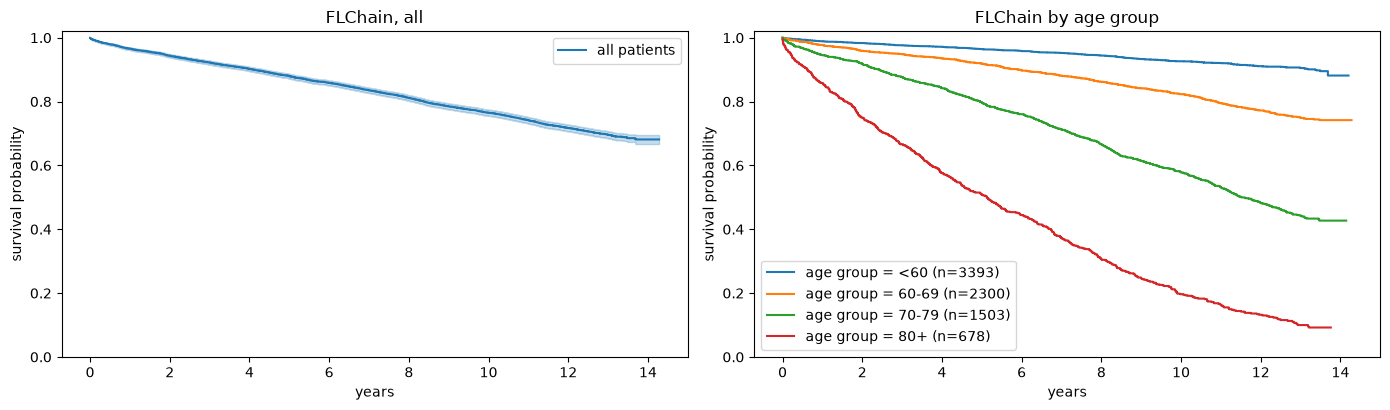

,chapter,creatinine
missing (%),72.5,17.1


In [4]:
df = data["FLChain"]
print(f"{len(df)} people, {df.event.mean():.0%} died during follow-up")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
km_plot(df, title="FLChain, all", ax=ax[0])
km_plot(df.assign(**{"age group": pd.cut(df.age, [0, 60, 70, 80, 120], labels=["<60", "60-69", "70-79", "80+"])}),
        by="age group", title="FLChain by age group", ax=ax[1])
plt.tight_layout(); plt.show()
missing(df).to_frame().T

`chapter` is missing for everyone who was still alive (it is the cause of death), which is why it would leak the outcome. Creatinine is missing for 17% of people; this is the real missingness used in notebook 07.

## 3. GBSG2

**German Breast Cancer Study Group 2.** 686 women with node-positive breast cancer from a randomised trial (1984-1989) of hormonal therapy and chemotherapy durations.

- **Event**: recurrence of the cancer or death (recurrence-free survival). **Time**: days (`time`).
- Small, few variables, no missing values. A hard dataset for every model in our results (C-index about 0.64-0.71).

| variable | meaning |
|---|---|
| `age`, `menostat` | age and menopausal status |
| `horTh` | received hormonal therapy (tamoxifen) |
| `tsize`, `tgrade` | tumour size (mm) and grade (I-III) |
| `pnodes` | number of positive lymph nodes |
| `progrec`, `estrec` | progesterone and oestrogen receptor levels (fmol) |

686 patients, 44% had a recurrence or died


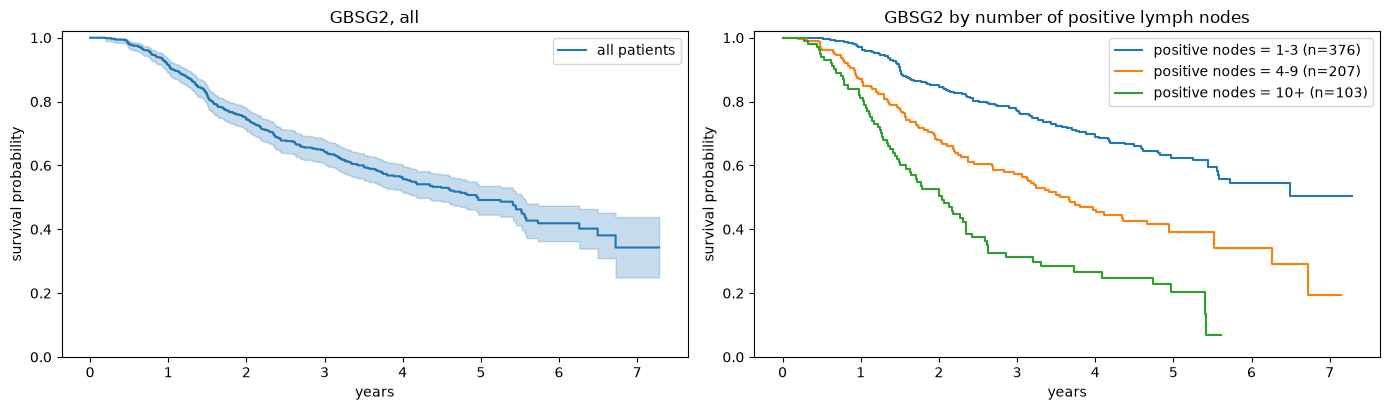

In [5]:
df = data["GBSG2"]
print(f"{len(df)} patients, {df.event.mean():.0%} had a recurrence or died")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
km_plot(df, title="GBSG2, all", ax=ax[0])
km_plot(df.assign(**{"positive nodes": pd.cut(df.pnodes, [0, 3, 9, 100], labels=["1-3", "4-9", "10+"])}),
        by="positive nodes", title="GBSG2 by number of positive lymph nodes", ax=ax[1])
plt.tight_layout(); plt.show()

## 4. WHAS500

**Worcester Heart Attack Study.** 500 patients admitted with an acute myocardial infarction (heart attack) to hospitals in Worcester, Massachusetts (a subset of the larger study, from Hosmer, Lemeshow & May, *Applied Survival Analysis*).

- **Event**: death (any cause). **Time**: days from admission to death or last follow-up (`lenfol`).

| variable | meaning |
|---|---|
| `age`, `gender` (0 = male, 1 = female), `bmi` | |
| `hr`, `sysbp`, `diasbp` | heart rate and blood pressure at admission |
| `afb`, `av3`, `sho`, `chf` | complications: atrial fibrillation, complete heart block, cardiogenic shock, congestive heart failure |
| `cvd` | history of cardiovascular disease |
| `miord`, `mitype` | recurrent vs first heart attack, Q-wave vs non-Q-wave |
| `los` | **length of hospital stay**: only known at discharge, not at admission, so we drop it in notebooks 07-09 (kept in 01) |

500 patients, 43% died during follow-up


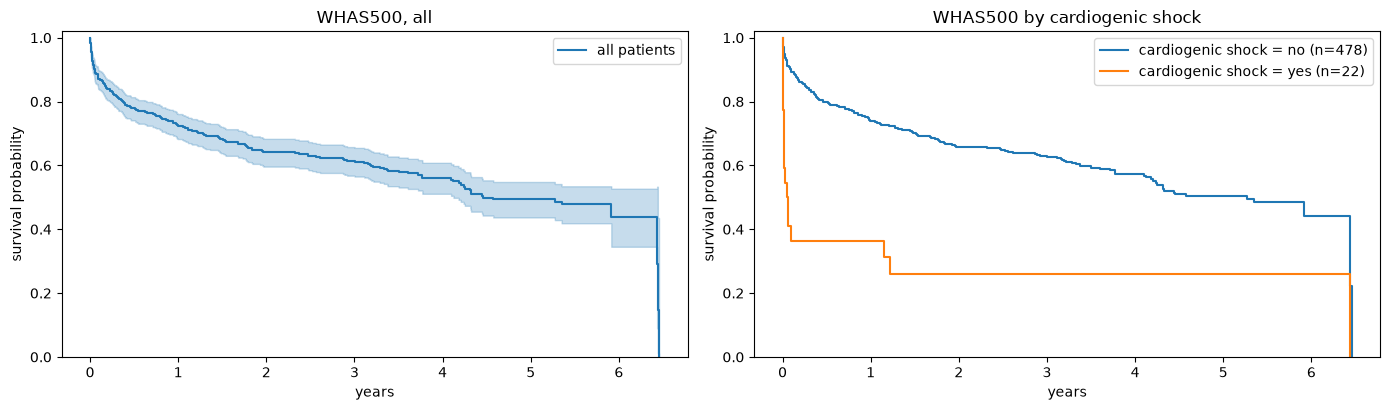

died during the hospital stay: 8%; their median stay 4 days vs 5 days for the others


In [6]:
df = data["WHAS500"]
print(f"{len(df)} patients, {df.event.mean():.0%} died during follow-up")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
km_plot(df, title="WHAS500, all", ax=ax[0])
km_plot(df.assign(**{"cardiogenic shock": df.sho.map({"0": "no", "1": "yes"})}), by="cardiogenic shock",
        title="WHAS500 by cardiogenic shock", ax=ax[1])
plt.tight_layout(); plt.show()
dead_in_hosp = (df.event == 1) & (df.time <= df.los)
print(f"died during the hospital stay: {dead_in_hosp.mean():.0%}; their median stay {df.los[dead_in_hosp].median():.0f} days "
      f"vs {df.los[~dead_in_hosp].median():.0f} days for the others")

## 5. Simulated data

The official VaDeSC generator (`src/simulate.py`, `simulate_nonlin_profile_surv`):

1. each patient belongs to one of K = 3 clusters (equal sizes),
2. a latent vector z is drawn from a cluster-specific Gaussian,
3. the features are a random non-linear function (a small random neural network) of z, so the clusters are not visible in any single feature,
4. survival time is Weibull with cluster-specific coefficients on z, so the clusters have different survival,
5. 30% of patients are censored at a random time before their event.

So, unlike the real data, the **true clusters are known** and clustering can be scored with ARI.

| setting | patients | features | used in |
|---|---|---|---|
| benchmark | 60,000 (02) / 10,000 (03, 08, 09) | 1,000 | 02, 03, 08, 09 |
| missingness experiments | 6,000 | 30 (cluster means in [-2, 2] instead of [-0.5, 0.5], easier to recover) | 06 |

10000 patients, 1000 features, 69% events, cluster sizes [3382, 3319, 3299]


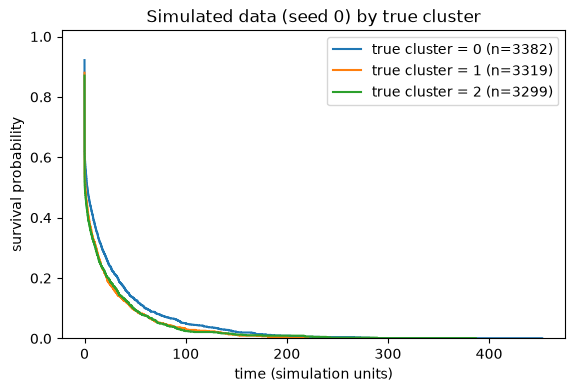

In [7]:
sim = load_simulated(n=10_000, p=1000, k=3, d_lat=16, seed=0)  # same as notebook 03, seed 0
t = np.concatenate([sim.t_tr, sim.t_va, sim.t_te]); e = np.concatenate([sim.e_tr, sim.e_va, sim.e_te])
c = np.concatenate([sim.clusters_true_tr, sim.clusters_true_va, sim.clusters_true_te])
print(f"{len(t)} patients, {sim.X_tr.shape[1]} features, {e.mean():.0%} events, cluster sizes {np.bincount(c).tolist()}")
sim_df = pd.DataFrame({"time": t * 365.25, "event": e, "true cluster": c})  # times have no unit; x365 so the plot shows them as is
ax = km_plot(sim_df, by="true cluster", title="Simulated data (seed 0) by true cluster")
ax.set_xlabel("time (simulation units)")
plt.show()

## 6. What our loaders do (`src/data.py`)

The same steps for every dataset:

1. **split**: 70% train, 10% validation, 20% test, stratified on the event indicator (default seed 42, so all notebooks use the same split unless they vary it),
2. **missing values**: numeric features filled with the training median, categorical with the most frequent training category (or kept as NaN / a "missing" category with `keep_missing=True`, notebooks 06-07),
3. **scaling**: numeric features standardised with training mean and std; categorical features one-hot encoded,
4. **SUPPORT only**: `totcst`, `charges`, `pafi`, `sod` log-transformed first; `drop_post_baseline=True` removes the 4 post-baseline variables,
5. **FLChain**: `chapter` (cause of death) dropped. **WHAS500**: `los` dropped in notebooks 07-09, kept in 01.

All fitting (medians, means, categories) uses the training set only.

In [8]:
shapes = []
for name, d in [("SUPPORT (paper preprocessing)", load_support()), ("SUPPORT (baseline-only)", load_support(drop_post_baseline=True)),
                ("FLChain", load_sksurv("FLChain")), ("GBSG2", load_sksurv("GBSG2")), ("WHAS500", load_sksurv("WHAS500"))]:
    shapes.append({"dataset": name, "train": len(d.X_tr), "validation": len(d.X_va), "test": len(d.X_te),
                   "model inputs (after one-hot)": d.X_tr.shape[1]})
pd.DataFrame(shapes).set_index("dataset")

,train,validation,test,model inputs (after one-hot)
dataset,,,,
SUPPORT (paper preprocessing),6373,911,1821,59
SUPPORT (baseline-only),6373,911,1821,51
FLChain,5511,788,1575,27
GBSG2,479,69,138,12
WHAS500,350,50,100,22


## 7. Summary

In [9]:
# FLChain without chapter (cause of death, dropped by our loader); SUPPORT still includes the 4 post-baseline variables
summ = pd.DataFrame([summary(n, d.drop(columns=["chapter"]) if n == "FLChain" else d) for n, d in data.items()])
summ["median survival (years)"] = summ["median survival (years)"].replace(np.inf, np.nan)  # FLChain: fewer than half died
summ = pd.concat([summ, pd.DataFrame([{"dataset": "Simulated (seed 0)", "patients": len(t), "variables": sim.X_tr.shape[1],
                                       "numeric": sim.X_tr.shape[1], "categorical": 0, "events (%)": 100 * e.mean(),
                                       "censored (%)": 100 * (1 - e.mean()), "missing cells (%)": 0.0,
                                       "patients with any missing (%)": 0.0}])], ignore_index=True)
summ = summ.set_index("dataset").round(1)
print("SUPPORT: 35 variables = 31 known at study entry + 4 post-baseline. NaN median survival = not reached (fewer than half the patients had the event); simulated times have no unit")
Path("../results/poster").mkdir(parents=True, exist_ok=True)
summ.to_csv("../results/poster/datasets.csv")
summ

SUPPORT: 35 variables = 31 known at study entry + 4 post-baseline. NaN median survival = not reached (fewer than half the patients had the event); simulated times have no unit


,patients,variables,numeric,categorical,events (%),censored (%),median follow-up (years),median survival (years),max time (years),missing cells (%),patients with any missing (%)
dataset,,,,,,,,,,,
SUPPORT,9105,35,28,7,68.1,31.9,2.8,0.6,5.6,12.6,96.2
FLChain,7874,8,4,4,27.5,72.5,12.7,NaN,14.3,2.1,17.1
GBSG2,686,8,5,3,43.6,56.4,4.5,4.9,7.3,0.0,0.0
WHAS500,500,14,6,8,43.0,57.0,3.6,4.5,6.5,0.0,0.0
Simulated (seed 0),10000,1000,1000,0,69.4,30.6,NaN,NaN,NaN,0.0,0.0


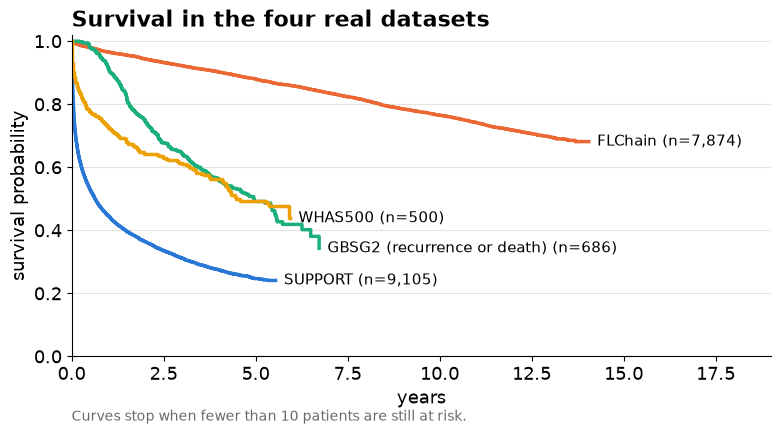

In [10]:
# figure for the poster: overall survival of the four real datasets on one time axis
COLORS = {"SUPPORT": "#2a78d6", "FLChain": "#eb6834", "GBSG2": "#1baf7a", "WHAS500": "#eda100"}
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 4.6))
for name, df in data.items():
    km = KaplanMeierFitter().fit(df["time"] / 365.25, df["event"])
    sf = km.survival_function_.iloc[:, 0]
    at_risk = km.event_table["at_risk"].reindex(sf.index)
    sf = sf[at_risk >= 10]  # cut the tail where fewer than 10 patients are still followed
    ax.step(sf.index, sf.values, where="post", color=COLORS[name], lw=2.5)
    ax.annotate(f"{name}{' (recurrence or death)' if name == 'GBSG2' else ''} (n={len(df):,})", (sf.index[-1], sf.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=11)
ax.set(xlabel="years", ylabel="survival probability", ylim=(0, 1.02), xlim=(0, 19))
ax.grid(True, axis="y", color="#e4e3de")
ax.set_title("Survival in the four real datasets", loc="left", fontweight="bold")
ax.text(0, -0.2, "Curves stop when fewer than 10 patients are still at risk.", transform=ax.transAxes, fontsize=10, color="#6b6a64")
plt.tight_layout()
Path("../figures").mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(f"../figures/datasets_km.{ext}", dpi=300, bbox_inches="tight")
plt.show()